# Unidad 2: Operaciones Vectorizadas y Álgebra Práctica
## Álgebra — Tecnicatura en Ciencia de Datos e IA

**Objetivos de esta notebook:**
- Comprender y demostrar la ventaja de velocidad de la vectorización sobre loops
- Aplicar broadcasting para operar datasets completos
- Usar producto punto y multiplicación matricial (`@`)
- Resolver sistemas de ecuaciones lineales con `np.linalg.solve`
- Implementar la Ecuación Normal para regresión lineal

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import time

dataset = np.array([
    [120.0,  3.0,  2.5, 180000.0],
    [ 85.0,  2.0,  1.0, 150000.0],
    [200.0,  4.0,  5.0, 250000.0],
    [ 60.0,  1.0,  0.5, 120000.0],
    [150.0,  3.0,  3.2, 210000.0]
])

X = dataset[:, 0:3]   # features
y = dataset[:, 3]     # precios

## 1. Vectorización vs Loops: el benchmark

Comparamos dos formas de calcular el doble de cada precio: con loop de Python y con NumPy.

In [4]:
N = 1_000_000
precios_grandes = np.random.randint(50000, 500000, size=N).astype(float)

# Con loop Python
start = time.time()
resultado_loop = []
for p in precios_grandes:
    resultado_loop.append(p * 2)
tiempo_loop = time.time() - start

# Con NumPy (vectorizado)
start = time.time()
resultado_numpy = precios_grandes * 2
tiempo_numpy = time.time() - start

print(f"Loop Python:  {tiempo_loop:.4f} segundos")
print(f"NumPy:        {tiempo_numpy:.4f} segundos")
print(f"NumPy es {tiempo_loop / tiempo_numpy:.0f}x más rápido")

Loop Python:  0.0876 segundos
NumPy:        0.0014 segundos
NumPy es 65x más rápido


## 2. Operaciones elemento a elemento y Broadcasting

Broadcasting permite operar arrays de distinta forma sin copiar datos.

In [5]:
# Operaciones escalares: se aplican a todos los elementos
print("Precios en miles (USD):\n", y / 1000)
print("\nPrecio con inflación del 8%:\n", y * 1.08)

Precios en miles (USD):
 [180. 150. 250. 120. 210.]

Precio con inflación del 8%:
 [194400. 162000. 270000. 129600. 226800.]


In [6]:
# Normalización Z-score: (x - media) / desvío estándar
# Broadcasting: X.shape=(5,3), media.shape=(3,) → se expande automáticamente
media = X.mean(axis=0)     # media de cada columna
std = X.std(axis=0)        # desvío estándar de cada columna

print("Media por feature:  ", media)
print("Desvío std por feature:", std)

X_norm = (X - media) / std
print("\nX normalizado:\n", X_norm.round(2))
print("\nVerificación — media post-norm:", X_norm.mean(axis=0).round(10))
print("Verificación — std post-norm:", X_norm.std(axis=0).round(10))

Media por feature:   [123.     2.6    2.44]
Desvío std por feature: [49.15282291  1.0198039   1.61071413]

X normalizado:
 [[-0.06  0.39  0.04]
 [-0.77 -0.59 -0.89]
 [ 1.57  1.37  1.59]
 [-1.28 -1.57 -1.2 ]
 [ 0.55  0.39  0.47]]

Verificación — media post-norm: [-0. -0.  0.]
Verificación — std post-norm: [1. 1. 1.]


## 3. Producto Punto: la predicción de un modelo

Si tengo pesos `w` para cada feature, la predicción de precio para una casa es el **producto punto** de sus features y esos pesos.

```
prediccion = size_m2 * w1 + rooms * w2 + distance_km * w3 + bias
```

In [7]:
# Pesos hipotéticos: precio ≈ 1200*m2 + 8000*rooms - 3000*dist
w = np.array([1200.0, 8000.0, -3000.0])

# Predicción para la primera casa
casa_1_features = X[0]
pred_manual = np.dot(casa_1_features, w)
print(f"Features casa 1: {casa_1_features}")
print(f"Pesos: {w}")
print(f"Predicción manual: ${pred_manual:,.0f}")
print(f"Precio real:       ${y[0]:,.0f}")

Features casa 1: [120.    3.    2.5]
Pesos: [ 1200.  8000. -3000.]
Predicción manual: $160,500
Precio real:       $180,000


In [8]:
# Predicción para TODAS las casas con multiplicación matricial
predicciones = X @ w   # (5,3) @ (3,) → (5,)

print("Predicciones para todas las casas:")
for i in range(len(y)):
    error = predicciones[i] - y[i]
    print(f"  Casa {i}: predicho=${predicciones[i]:>10,.0f} | real=${y[i]:>10,.0f} | error={error:>+,.0f}")

Predicciones para todas las casas:
  Casa 0: predicho=$   160,500 | real=$   180,000 | error=-19,500
  Casa 1: predicho=$   115,000 | real=$   150,000 | error=-35,000
  Casa 2: predicho=$   257,000 | real=$   250,000 | error=+7,000
  Casa 3: predicho=$    78,500 | real=$   120,000 | error=-41,500
  Casa 4: predicho=$   194,400 | real=$   210,000 | error=-15,600


## 4. Transposición de Matrices

In [9]:
print("X shape:", X.shape)       # (5, 3)
print("X.T shape:", X.T.shape)   # (3, 5)

print("\nX (features):\n", X)
print("\nX transpuesta (X.T):\n", X.T)

# X.T @ X es la matriz de covarianza (usada en Ecuación Normal)
cov_matrix = X_norm.T @ X_norm / len(X_norm)
print("\nMatriz de covarianza (X_norm.T @ X_norm / n):\n", cov_matrix.round(3))

X shape: (5, 3)
X.T shape: (3, 5)

X (features):
 [[120.    3.    2.5]
 [ 85.    2.    1. ]
 [200.    4.    5. ]
 [ 60.    1.    0.5]
 [150.    3.    3.2]]

X transpuesta (X.T):
 [[120.   85.  200.   60.  150. ]
 [  3.    2.    4.    1.    3. ]
 [  2.5   1.    5.    0.5   3.2]]

Matriz de covarianza (X_norm.T @ X_norm / n):
 [[1.    0.962 0.996]
 [0.962 1.    0.959]
 [0.996 0.959 1.   ]]


## 5. Resolver Sistemas de Ecuaciones Lineales

Un sistema `Ax = b` se resuelve con `np.linalg.solve`.

**Ejemplo:** tenemos 3 casas y 3 incógnitas (w1, w2, w3). Queremos encontrar los pesos exactos que reproducen los precios reales:

```
120*w1 + 3*w2 + 2.5*w3 = 180000
 85*w1 + 2*w2 + 1.0*w3 = 150000
200*w1 + 4*w2 + 5.0*w3 = 250000
```

In [10]:
# Sistema cuadrado: 3 ecuaciones, 3 incógnitas
A = X[:3, :]           # primeras 3 casas como matriz de coeficientes
b = y[:3]              # sus precios reales

print("Sistema Ax = b")
print("A:\n", A)
print("b:", b)

solucion = np.linalg.solve(A, b)
print("\nSolución (w1, w2, w3):", solucion.round(2))

# Verificar: A @ solución debe dar b
verificacion = A @ solucion
print("Verificación A @ x:", verificacion.round(1))
print("b original:        ", b)

Sistema Ax = b
A:
 [[120.    3.    2.5]
 [ 85.    2.    1. ]
 [200.    4.    5. ]]
b: [180000. 150000. 250000.]

Solución (w1, w2, w3): [  1619.05  22619.05 -32857.14]
Verificación A @ x: [180000. 150000. 250000.]
b original:         [180000. 150000. 250000.]


## 6. La Ecuación Normal: regresión lineal algebraica

Para datasets con más muestras que incógnitas (sobredeterminado), la **Ecuación Normal** minimiza el MSE directamente:

$$\hat{\theta} = (X^T X)^{-1} X^T y$$

Agregamos una columna de 1s a `X` para incluir el término independiente (`bias`).

In [11]:
# Agregar columna de 1s (bias term)
ones = np.ones((len(X), 1))
X_b = np.hstack([ones, X])   # (5, 4): bias + 3 features
print("X aumentada (con bias):\n", X_b)

# Ecuación Normal
theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
print("\nParámetros óptimos (θ):")
print(f"  bias    = {theta[0]:,.0f}")
print(f"  w_m2    = {theta[1]:,.1f} (por cada m² adicional)")
print(f"  w_rooms = {theta[2]:,.1f} (por habitación adicional)")
print(f"  w_dist  = {theta[3]:,.1f} (por km de distancia)")

X aumentada (con bias):
 [[  1.  120.    3.    2.5]
 [  1.   85.    2.    1. ]
 [  1.  200.    4.    5. ]
 [  1.   60.    1.    0.5]
 [  1.  150.    3.    3.2]]

Parámetros óptimos (θ):
  bias    = 42,651
  w_m2    = 1,324.7 (por cada m² adicional)
  w_rooms = 5,964.8 (por habitación adicional)
  w_dist  = -16,024.9 (por km de distancia)


In [12]:
# Predicciones con los parámetros óptimos
y_pred = X_b @ theta
mse = np.mean((y_pred - y) ** 2)

print("Predicciones vs valores reales:")
for i in range(len(y)):
    print(f"  Casa {i}: predicho=${y_pred[i]:>10,.0f} | real=${y[i]:>10,.0f}")

print(f"\nMSE: {mse:,.0f}")
print(f"RMSE (error en $): ${np.sqrt(mse):,.0f}")

Predicciones vs valores reales:
  Casa 0: predicho=$   179,450 | real=$   180,000
  Casa 1: predicho=$   151,157 | real=$   150,000
  Casa 2: predicho=$   251,331 | real=$   250,000
  Casa 3: predicho=$   120,087 | real=$   120,000
  Casa 4: predicho=$   207,975 | real=$   210,000

MSE: 1,504,563
RMSE (error en $): $1,227


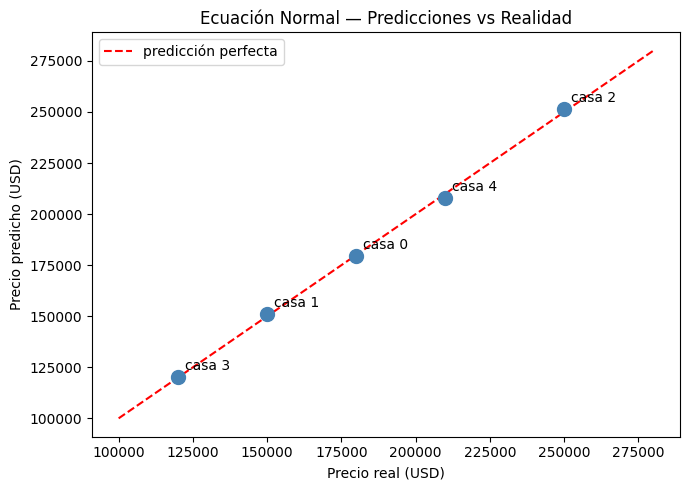

In [13]:
# Visualizar predicciones vs valores reales
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y, y_pred, color='steelblue', s=100, zorder=5)
lim = [100000, 280000]
ax.plot(lim, lim, 'r--', linewidth=1.5, label='predicción perfecta')
for i in range(len(y)):
    ax.annotate(f'casa {i}', (y[i], y_pred[i]), textcoords='offset points', xytext=(5, 5))
ax.set_xlabel('Precio real (USD)')
ax.set_ylabel('Precio predicho (USD)')
ax.set_title('Ecuación Normal — Predicciones vs Realidad')
ax.legend()
plt.tight_layout()
plt.show()

## Ejercicios

**Ejercicio 1:** Normalizá el vector `y` (precios) usando Z-score. ¿Cuáles son su media y desvío estándar después de normalizar?

**Ejercicio 2:** Calculá la predicción de precio para una casa nueva con 130 m², 3 habitaciones y 1.5 km del centro, usando el vector `theta` calculado con la Ecuación Normal.

**Ejercicio 3:** ¿Qué pasa si en la Ecuación Normal usás `np.linalg.solve` en lugar de `np.linalg.inv`? Reescribí el cálculo de `theta` usando `np.linalg.solve`. *(Pista: `(X.T @ X) @ theta = X.T @ y`)*

In [14]:
# Ejercicio 1


In [15]:
# Ejercicio 2


In [16]:
# Ejercicio 3
